# Лабораторная работа №6 Романов Михаил ПМИ-3


In [1]:
import json, os, re, shutil, sqlite3, time, unicodedata
from datetime import datetime, timezone, timedelta
from decimal import Decimal
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pyarrow as pa
import pyarrow.parquet as pq

pd.set_option("display.width", 190)
pd.set_option("display.max_columns", 40)
plt.rcParams["figure.figsize"] = (8, 4)

ROOT = Path("Z:/Work/ED/4trim/parsing/6lab").resolve()
for sub in ("raw", "clean", "mart/views", "mart/snapshots", "db", "src", "nocode"):
    (ROOT / sub).mkdir(parents=True, exist_ok=True)

PARSER_VERSION = "lab6/1.0"
def NOW_UTC():
    return datetime.now(timezone.utc).isoformat(timespec="seconds")

print("ROOT:", ROOT)
print("Каталоги:", [p.name + "/" for p in sorted(ROOT.iterdir()) if p.is_dir()])


ROOT: Z:\Work\ED\4trim\parsing\6lab
Каталоги: ['clean/', 'db/', 'mart/', 'nocode/', 'raw/', 'src/']


## 1. Слой raw. объединение источников + метаданные происхождения

Первый источник HTML-каталог (Scrapy, книги). Вместе с полезными полями сохраняем их сырое значение (`price_raw`, `stock_raw`, `rating_raw`), чтобы `clean` можно было перепарсить без сайта.Заодно пишем метаданные происхождения URL, время сбора, версию парсера, код ответа

Второй источник это REST API (JSONPlaceholder, комментарии). Он приводится к той же схеме, у него нет «цены» и остатка, поэтому эти поля синтезируются детерминированно из идентификатора


In [ ]:
raw_records = []

# --- Источник 1: 5lab Scrapy (HTML), книги
p5 = Path("Z:/Work/ED/4trim/parsing/5lab/lab5_6/data/items.jsonl")
with p5.open("r", encoding="utf-8") as f:
    for line in f:
        line = line.strip()
        if not line:
            continue
        d = json.loads(line)
        # в файле 5lab смешаны книги и цитаты — берём только книги (схема «товар»)
        if d.get("source") != "books":
            continue
        title = d.get("title") or ""
        url = d.get("url") or d.get("list_url") or ""
        upc = d.get("upc") or ""
        price_raw = d.get("list_price")
        qty = d.get("quantity")
        rating = d.get("rating")
        try:
            qty_i = int(qty) if qty is not None and str(qty).strip() != "" else None
        except Exception:
            qty_i = None
        try:
            r_i = int(rating) if rating is not None and str(rating).strip() != "" else None
        except Exception:
            r_i = None
        try:
            price_v = float(price_raw) if price_raw is not None else None
        except Exception:
            price_v = None
        raw_records.append({
            "title": title,
            "price_raw": price_raw,          # сырое значение «как со страницы»
            "price_num": price_v,
            "stock_raw": qty,
            "stock_num": qty_i,
            "rating_raw": rating,
            "rating_num": r_i,
            "category": d.get("category"),
            "in_stock_raw": d.get("availability"),
            "detail_url": url,
            "business_key_raw": upc or (url.rsplit("/", 2)[-2] if url else ""),
            "_source": "scrapy.books",
            "_source_url": url or str(p5),
            "_collected_at": NOW_UTC(),
            "_parser_version": PARSER_VERSION,
            "_status": 200,
        })

n_books = len(raw_records)

# --- Источник 2: 3lab REST API (comments)
p3 = Path("Z:/Work/ED/4trim/parsing/3lab/data_raw.jsonl")
with p3.open("r", encoding="utf-8") as f:
    for line in f:
        line = line.strip()
        if not line:
            continue
        try:
            d3 = json.loads(line)
        except Exception:
            continue
        if d3.get("_source") != "jsonplaceholder.comments":
            continue
        payload = d3.get("payload") or {}
        cid = payload.get("id")
        name = payload.get("name") or payload.get("email") or ""
        body = payload.get("body") or ""
        url_c = d3.get("_source_url") or "https://jsonplaceholder.typicode.com/comments"
        title_c = (name[:80] + ("..." if len(name) > 80 else "")) if name else body[:60]
        price_v = 10.0 + (cid % 50) if isinstance(cid, int) else 15.0
        stock_v = 1 + (cid % 20) if isinstance(cid, int) else 5
        rating_v = 1 + (cid % 5) if isinstance(cid, int) else 3
        raw_records.append({
            "title": title_c,
            "price_raw": price_v,
            "price_num": price_v,
            "stock_raw": stock_v,
            "stock_num": stock_v,
            "rating_raw": rating_v,
            "rating_num": rating_v,
            "category": "Comments",
            "in_stock_raw": "In stock",
            "detail_url": f"{url_c}/{cid}" if cid is not None else url_c,
            "business_key_raw": f"c_{cid}" if cid is not None else "",
            "_source": d3.get("_source") or "jsonplaceholder.comments",
            "_source_url": url_c,
            "_collected_at": d3.get("_collected_at") or NOW_UTC(),
            "_parser_version": d3.get("_parser_version") or PARSER_VERSION,
            "_status": 200,
        })

print("Книги (HTML/Scrapy):", n_books)
print("Комментарии (API):", len(raw_records) - n_books)
print("Всего сырых записей:", len(raw_records))


Книги (HTML/Scrapy): 465
Комментарии (API): 500
Всего сырых записей: 965


In [3]:
# Записываем в raw/ JSON Lines строго в режиме дозаписи: файл НЕ удаляется и НЕ перезаписывается
books_list = [r for r in raw_records if r["_source"] == "scrapy.books"]
comm_list = [r for r in raw_records if r["_source"] != "scrapy.books"]

RAW_BOOKS = ROOT / "raw" / "scrapy_books.jsonl"
RAW_COMM = ROOT / "raw" / "api_comments.jsonl"

def _raw_identity(rec):
    """Идентичность записи без метки времени: уже записанная строка повторно не добавляется."""
    return json.dumps({k: v for k, v in rec.items() if k != "_collected_at"},
                      ensure_ascii=False, sort_keys=True, default=str)

def append_jsonl(path, records):
    """Дозапись в raw. Существующие строки не изменяются; дубли по содержимому пропускаются,
    поэтому повторный прогон не создаёт дублей и не перезаписывает собранные ранее данные."""
    seen = set()
    if path.exists():
        for line in path.open(encoding="utf-8"):
            line = line.strip()
            if line:
                seen.add(_raw_identity(json.loads(line)))
    added = 0
    with path.open("a", encoding="utf-8") as f:      # режим "a": только дозапись
        for r in records:
            ident = _raw_identity(r)
            if ident in seen:
                continue
            seen.add(ident)
            f.write(json.dumps(r, ensure_ascii=False) + "\n")
            added += 1
    return added

added_books = append_jsonl(RAW_BOOKS, books_list)
added_comm = append_jsonl(RAW_COMM, comm_list)
print(f"дописано новых строк: scrapy_books={added_books}, api_comments={added_comm}")
print("raw/scrapy_books.jsonl:", RAW_BOOKS.stat().st_size, "байт")
print("raw/api_comments.jsonl:", RAW_COMM.stat().st_size, "байт")
print("\nПервая строка сырого слоя:")
rec = json.loads(RAW_BOOKS.open(encoding="utf-8").readline())
print(json.dumps(rec, ensure_ascii=False, indent=2)[:600])


дописано новых строк: scrapy_books=0, api_comments=0
raw/scrapy_books.jsonl: 284056 байт
raw/api_comments.jsonl: 253612 байт

Первая строка сырого слоя:
{
  "title": "It's Only the Himalayas",
  "price_raw": 45.17,
  "price_num": 45.17,
  "stock_raw": 19,
  "stock_num": 19,
  "rating_raw": 2,
  "rating_num": 2,
  "category": "Travel",
  "in_stock_raw": "In stock (19 available)",
  "detail_url": "https://books.toscrape.com/catalogue/its-only-the-himalayas_981/index.html",
  "business_key_raw": "a22124811bfa8350",
  "_source": "scrapy.books",
  "_source_url": "https://books.toscrape.com/catalogue/its-only-the-himalayas_981/index.html",
  "_collected_at": "2026-10-19T13:49:24+00:00",
  "_parser_version": "lab6/1.0",
  "_status": 200
}


Данные сохранены в два JSON-файла

### Смоделированный мусор

Любой реальный сбор приносит проблемные записи. Готовил 7 испорченных записей, почти-дубль (URL с трекингом), неразобранная цена, пустой обязательный заголовок, неразрывные пробелы, отрицательная цена, полный дубль, конфликт «в наличии, но остаток 0».




In [4]:
dirty = [
    # 1. дубль книги по URL с параметром трекинга (почти-дубль)
    {**books_list[1], "detail_url": books_list[1]["detail_url"] + "?utm_source=newsletter"},
    # 2. цена не разобралась (сайт отдал заглушку)
    {**books_list[2], "price_raw": "Цена по запросу", "price_num": None},
    # 3. пропуск обязательного поля title
    {**books_list[3], "title": ""},
    # 4. неразрывные пробелы и лишние переводы строк
    {**books_list[4], "title": "  Sharp\xa0\xa0Objects \n"},
    # 5. отрицательная цена — ошибка парсинга
    {**books_list[5], "price_raw": -12.0, "price_num": -12.0},
    # 6. полный дубль записи (сбой повторной попытки)
    {**books_list[6]},
    # 7. «в наличии», но остаток 0 — конфликт бизнес-правил
    {**books_list[7], "stock_raw": 0, "stock_num": 0},
]

dirty_added = append_jsonl(RAW_BOOKS, dirty)   # та же дозапись: файл не перезаписывается
print("дописано «мусорных» строк:", dirty_added, "из", len(dirty),
      "(полный дубль отсекается уже здесь — append-only не допускает повторной записи)")

raw_df_all = pd.concat(
    [pd.read_json(RAW_BOOKS, lines=True), pd.read_json(RAW_COMM, lines=True)],
    ignore_index=True)
raw_df_all["_raw_pos"] = range(len(raw_df_all))   # позиция в raw: позднейшая дозапись побеждает при равном времени
print("Строк в сыром слое (с мусором):", len(raw_df_all))
raw_df_all[["title", "price_raw", "stock_raw", "rating_raw", "_source"]].tail(7)


дописано «мусорных» строк: 0 из 7 (полный дубль отсекается уже здесь — append-only не допускает повторной записи)
Строк в сыром слое (с мусором): 972


,title,price_raw,stock_raw,rating_raw,_source
965,molestias facere soluta mollitia totam dolorem...,54,15,5,jsonplaceholder.comments
966,dolor ut ut aut molestiae esse et tempora numquam,55,16,1,jsonplaceholder.comments
967,et occaecati asperiores quas voluptas ipsam no...,56,17,2,jsonplaceholder.comments
968,doloribus dolores ut dolores occaecati,57,18,3,jsonplaceholder.comments
969,dolores minus aut libero,58,19,4,jsonplaceholder.comments
970,excepturi sunt cum a et rerum quo voluptatibus...,59,20,5,jsonplaceholder.comments
971,ex eaque eum natus,10,1,1,jsonplaceholder.comments


## 2. Сравнение форматов хранения(CSV / JSON Lines / Parquet)

Один и тот же набор сохраняем в три формата и сравниваем размер, время полного чтения, время чтения двух столбцов и,самое важное,сохранность типов (дата и строковый артикул с ведущим нулём)


In [5]:
bench = raw_df_all.copy()
# в бенчмарке «сырые» колонки приводим к строке: Parquet не любит смешанный тип object
bench["price_raw"] = bench["price_raw"].astype(str)
bench["stock_raw"] = bench["stock_raw"].astype(str)
bench["rating_raw"] = bench["rating_raw"].astype(str)
bench["price_num"] = pd.to_numeric(bench["price_num"], errors="coerce")
bench["collected_at_dt"] = pd.to_datetime(bench["_collected_at"], utc=True, format="mixed", errors="coerce")
bench["sku"] = [f"{1000 + i:05d}" for i in range(len(bench))]   # артикул с ведущим нулём

bench_big = pd.concat([bench] * 20, ignore_index=True)          # размножим для наглядности замера

p_csv = ROOT / "clean" / "bench_fmt.csv"
p_jl = ROOT / "clean" / "bench_fmt.jsonl"
p_pq = ROOT / "clean" / "bench_fmt.parquet"
for x in (p_csv, p_jl, p_pq):
    x.unlink(missing_ok=True)

bench_big.to_csv(p_csv, index=False)
bench_big.to_json(p_jl, orient="records", lines=True, force_ascii=False, date_format="iso")
bench_big.to_parquet(p_pq, index=False, compression="snappy")

res = []
for name, p in [("CSV", p_csv), ("JSONL", p_jl), ("Parquet", p_pq)]:
    t0 = time.perf_counter()
    if name == "CSV":
        full = pd.read_csv(p)
    elif name == "JSONL":
        full = pd.read_json(p, lines=True)
    else:
        full = pd.read_parquet(p)
    t_full = time.perf_counter() - t0

    t0 = time.perf_counter()
    if name == "Parquet":
        pd.read_parquet(p, columns=["title", "price_num"])       # чтение только 2 столбцов
    elif name == "CSV":
        pd.read_csv(p, usecols=["title", "price_num"])
    else:
        pd.read_json(p, lines=True)[["title", "price_num"]]
    t_two = time.perf_counter() - t0

    res.append({
        "формат": name,
        "строк": len(full),
        "размер, КБ": round(p.stat().st_size / 1024, 1),
        "чтение всего, мс": round(t_full * 1000),
        "чтение 2 столбцов, мс": round(t_two * 1000),
        "тип price_num": str(full["price_num"].dtype),
        "тип collected_at": str(full["collected_at_dt"].dtype) if "collected_at_dt" in full else "object",
        "sku (ведущий ноль)": str(full["sku"].iloc[0]),
    })

fmt_bench = pd.DataFrame(res).sort_values("формат").reset_index(drop=True)
fmt_bench.to_csv(ROOT / "clean" / "format_benchmark.csv", index=False)
fmt_bench


,формат,строк,"размер, КБ","чтение всего, мс","чтение 2 столбцов, мс",тип price_num,тип collected_at,sku (ведущий ноль)
0,CSV,19440,6249.2,72,41,float64,object,1000
1,JSONL,19440,11551.5,226,311,float64,object,1000
2,Parquet,19440,122.0,44,4,float64,"datetime64[ns, UTC]",01000


Сравнил размер и время чтения трёх форматов

In [6]:
csv_kb = float(fmt_bench.loc[fmt_bench["формат"] == "CSV", "размер, КБ"].iloc[0])
jl_kb = float(fmt_bench.loc[fmt_bench["формат"] == "JSONL", "размер, КБ"].iloc[0])
pq_kb = float(fmt_bench.loc[fmt_bench["формат"] == "Parquet", "размер, КБ"].iloc[0])
print(f"Parquet меньше CSV в {csv_kb / pq_kb:.1f} раза и меньше JSONL в {jl_kb / pq_kb:.1f} раза.")
print("CSV теряет тип datetime (становится object) и ведущий ноль артикула (1000 вместо 01000).")
print("Parquet сохраняет и типы, и ведущий ноль, и читает только нужные столбцы.")


Parquet меньше CSV в 51.2 раза и меньше JSONL в 94.7 раза.
CSV теряет тип datetime (становится object) и ведущий ноль артикула (1000 вместо 01000).
Parquet сохраняет и типы, и ведущий ноль, и читает только нужные столбцы.


Parquet занимает меньше места и сохраняет типы данных. В CSV дата стала строкой, а артикул потерял ведущий ноль

## 3. Очистка: шесть шагов в фиксированной последовательности

Порядок: нормализация текста -> бизнес-ключ -> типизация -> пропуски -> дубликаты -> бизнес правила


In [7]:
def norm_text(v):
    if not isinstance(v, str):
        return None
    v = unicodedata.normalize("NFKC", v).replace("\xa0", " ")     # NFKC + неразрывный пробел
    v = re.sub(r"[\u200b-\u200d\ufeff]", "", v)                  # zero-width
    v = re.sub(r"\s+", " ", v).strip()
    return v or None

df = raw_df_all.copy()
log = []

def step(n, name, before, after, note=""):
    log.append({"№": n, "шаг": name, "строк до": int(before), "строк после": int(after),
                "изменено/удалено": int(before - after), "примечание": note})

start_rows = len(df)

# --- Шаг 1. Нормализация текста
changed_txt = int((df["title"].map(norm_text) != df["title"]).sum())
df["title"] = df["title"].map(norm_text)
df["category"] = df["category"].map(norm_text)
step(1, "нормализация текста", start_rows, len(df), f"исправлено title: {changed_txt}")

# --- Шаг 2. Бизнес-ключ (стабильный; URL с параметрами трекинга нормализуется)
def make_key(r):
    bk = r.get("business_key_raw") or ""
    bk = bk.strip() if isinstance(bk, str) else ""
    if bk:
        return re.sub(r"\s+", "", bk)
    du = (r.get("detail_url") or "").split("?")[0].rstrip("/")     # отбрасываем ?utm_...
    m = re.search(r"/([A-Za-z0-9_-]+)_(\d+)$", du)
    if m:
        return f"{m.group(1)}_{m.group(2)}"
    return "gen_" + str(abs(hash((r.get("title") or "", du))) % 10**10)

df["product_key"] = df.apply(make_key, axis=1)
step(2, "бизнес-ключ", len(df), len(df), "стабильный ключ, URL без параметров трекинга")
print("Пример бизнес-ключа:", df["product_key"].iloc[0])

# --- Шаг 3. Типизация
df["price"] = pd.to_numeric(df["price_num"], errors="coerce")       # деньги -> numeric (Decimal в контракте)
df["stock"] = pd.to_numeric(df["stock_num"], errors="coerce").astype("Int64")   # nullable-целое
df["rating"] = pd.to_numeric(df["rating_num"], errors="coerce").astype("Int64")
df["in_stock"] = df["in_stock_raw"].astype(str).str.contains("in stock", case=False, na=False)
df["collected_at_dt"] = pd.to_datetime(df["_collected_at"], utc=True, format="mixed", errors="coerce")  # UTC
bad_price = int(df["price"].isna().sum())
step(3, "типизация", len(df), len(df), f"цена не разобралась: {bad_price}")
print(df[["price", "stock", "rating", "in_stock", "collected_at_dt"]].dtypes.to_string())


Пример бизнес-ключа: a22124811bfa8350
price                          float64
stock                            Int64
rating                           Int64
in_stock                          bool
collected_at_dt    datetime64[ns, UTC]


Текст очищен от лишних символов, поля приведены к нужным типам. Цена "по запросу" не распознана.

In [8]:
# --- Шаг 4. Пропуски: обязательные поля -> отбраковка с причиной
required = ["title", "product_key", "price"]
mask_missing = df[required].isna().any(axis=1)
print("Записей с пропуском обязательных полей:", int(mask_missing.sum()))
display(df.loc[mask_missing, ["title", "price_raw", "price", "product_key"]])

rejects = df[mask_missing].copy()
if len(rejects):
    rejects["reject_reason"] = "пропуск обязательного поля"
before = len(df)
df = df[~mask_missing].copy()
step(4, "пропуски обязательных полей", before, len(df), f"в rejects: {len(rejects)}")

print("\nПолнота полей после шага (необязательные НЕ заполняем средним — остаются NULL):")
print((df.notna().mean() * 100).round(1)[["title", "price", "stock", "rating"]].to_string())


Записей с пропуском обязательных полей: 2


,title,price_raw,price,product_key
466,Olio,Цена по запросу,NaN,feb7cc7701ecf901
467,None,37.59,37.59,e30f54cea9b38190



Полнота полей после шага (необязательные НЕ заполняем средним — остаются NULL):
title     100.0
price     100.0
stock     100.0
rating    100.0


Записи без обязательных полей попали в rejects

In [9]:
# --- Шаг 5. Дубликаты: полные, по бизнес-ключу и почти-дубли (URL с параметрами)
full_duples = int(df.duplicated(subset=[c for c in df.columns if not c.startswith("_")]).sum())
key_duples = int(df.duplicated(subset=["product_key"]).sum())
print(f"Полных дублей: {full_duples} | дублей по бизнес-ключу: {key_duples}")
display(df[df.duplicated(subset=["product_key"], keep=False)]
        [["product_key", "title", "detail_url", "collected_at_dt"]].sort_values("product_key").head(6))

before = len(df)
df = (df.sort_values(["collected_at_dt", "_raw_pos"])      # равное время -> побеждает позднейшая строка raw
        .drop_duplicates(subset=["product_key"], keep="last") # оставляем самую свежую версию
        .reset_index(drop=True))
step(5, "дедупликация по ключу", before, len(df), "сохранена самая свежая версия")
print(f"После дедупликации: {len(df)} записей, уникальных ключей: {df['product_key'].nunique()}")


Полных дублей: 1 | дублей по бизнес-ключу: 5


,product_key,title,detail_url,collected_at_dt
5,3b1c02bac2a429e6,Scott Pilgrim's Precious Little Life (Scott Pi...,https://books.toscrape.com/catalogue/scott-pil...,2026-10-19 13:49:24+00:00
469,3b1c02bac2a429e6,Scott Pilgrim's Precious Little Life (Scott Pi...,https://books.toscrape.com/catalogue/scott-pil...,2026-10-19 13:49:24+00:00
1,a18a4f574854aced,Libertarianism for Beginners,https://books.toscrape.com/catalogue/libertari...,2026-10-19 13:49:24+00:00
465,a18a4f574854aced,Libertarianism for Beginners,https://books.toscrape.com/catalogue/libertari...,2026-10-19 13:49:24+00:00
7,a34ba96d4081e6a4,Rip it Up and Start Again,https://books.toscrape.com/catalogue/rip-it-up...,2026-10-19 13:49:24+00:00
471,a34ba96d4081e6a4,Rip it Up and Start Again,https://books.toscrape.com/catalogue/rip-it-up...,2026-10-19 13:49:24+00:00


После дедупликации: 965 записей, уникальных ключей: 965


Дубликаты найдены по ключу товара. Из каждой группы оставлена последняя запись

In [10]:
# --- Шаг 6. Бизнес-правила (>=5), специфичные для товарного каталога
RULES = {
    "цена > 0":                       df["price"] > 0,
    "цена < 10000":                   df["price"] < 10000,
    "рейтинг 1..5":                   df["rating"].isna() | df["rating"].between(1, 5),
    "остаток >= 0":                   df["stock"].isna() | (df["stock"] >= 0),
    "наличие согласовано с остатком": ~(df["in_stock"] & df["stock"].notna() & (df["stock"] == 0)),
    "ключ не пустой":                 df["product_key"].str.len() > 0,
}
checks = pd.DataFrame([{"правило": k, "нарушений": int((~v).sum()),
                        "доля, %": round(float((~v).mean() * 100), 2)}
                       for k, v in RULES.items()])
display(checks)

violated = ~pd.concat(list(RULES.values()), axis=1).all(axis=1)
rej_rules = df[violated].copy()
if len(rej_rules):
    rej_rules["reject_reason"] = "нарушение бизнес-правила"
rejects = pd.concat([rejects, rej_rules], ignore_index=True, sort=False)
before = len(df)
df = df[~violated].reset_index(drop=True)
step(6, "бизнес-правила", before, len(df), f"итого в rejects: {len(rejects)}")

protocol = pd.DataFrame(log)
protocol


,правило,нарушений,"доля, %"
0,цена > 0,1,0.1
1,цена < 10000,0,0.0
2,рейтинг 1..5,0,0.0
3,остаток >= 0,0,0.0
4,наличие согласовано с остатком,1,0.1
5,ключ не пустой,0,0.0


,№,шаг,строк до,строк после,изменено/удалено,примечание
0,1,нормализация текста,972,972,0,исправлено title: 2
1,2,бизнес-ключ,972,972,0,"стабильный ключ, URL без параметров трекинга"
2,3,типизация,972,972,0,цена не разобралась: 1
3,4,пропуски обязательных полей,972,970,2,в rejects: 2
4,5,дедупликация по ключу,970,965,5,сохранена самая свежая версия
5,6,бизнес-правила,965,963,2,итого в rejects: 4


Записи с нарушениями правил отбракованы. Причины сохраненил для проверок

## 4. Контракт данных (Pydantic)

Модель задаёт типы, обязательность, ограничения диапазонов, собственные валидаторы и проверку согласованности полей. Применяется на границе raw и clean. Невалидные записи попадают в rejects с указанием поля и причины


In [11]:
from pydantic import BaseModel, Field, ValidationError, field_validator, model_validator

class Product(BaseModel):
    product_key: str = Field(min_length=1, max_length=200)       # бизнес-ключ
    title: str = Field(min_length=1, max_length=300)
    price: Decimal = Field(gt=0, le=10000, decimal_places=2)     # деньги — Decimal, не float
    stock: int | None = Field(default=None, ge=0, le=1_000_000)
    rating: int | None = Field(default=None, ge=1, le=5)
    category: str | None = None
    in_stock: bool
    source: str
    source_url: str
    parser_version: str
    collected_at: datetime

    @field_validator("title")
    @classmethod
    def v_title(cls, v):
        return " ".join(unicodedata.normalize("NFKC", v).split())

    @field_validator("source_url")
    @classmethod
    def v_url(cls, v):
        if not v.startswith(("http://", "https://")):
            raise ValueError("URL должен начинаться с http(s)://")
        return v.split("?")[0]

    @field_validator("category")
    @classmethod
    def v_cat(cls, v):
        if v is None:
            return v
        return " ".join(unicodedata.normalize("NFKC", v).split()) or None

    @model_validator(mode="after")
    def v_consistency(self):
        # согласованность полей: нельзя быть «в наличии» без остатка
        if self.in_stock and self.stock is not None and self.stock == 0:
            raise ValueError("несогласованно: in_stock=True при stock=0")
        return self


def row2payload(r):
    price = Decimal(str(round(float(r["price"]), 2))) if pd.notna(r["price"]) else Decimal("0")
    ca = r["collected_at_dt"]
    return {
        "product_key": r["product_key"], "title": r["title"], "price": price,
        "stock": None if pd.isna(r["stock"]) else int(r["stock"]),
        "rating": None if pd.isna(r["rating"]) else int(r["rating"]),
        "category": r.get("category"), "in_stock": bool(r["in_stock"]),
        "source": r["_source"], "source_url": r["detail_url"] or r["_source_url"],
        "parser_version": r["_parser_version"],
        "collected_at": ca.to_pydatetime() if pd.notna(ca) else datetime.now(timezone.utc),
    }

valid_list, invalid_list = [], []
for _, rr in df.iterrows():
    try:
        valid_list.append(Product(**row2payload(rr)))
    except ValidationError as e:
        err = e.errors()[0]
        invalid_list.append({"product_key": rr.get("product_key"),
                             "поле": ".".join(map(str, err["loc"])),
                             "причина": err["msg"]})

print(f"Прошли контракт: {len(valid_list)} | отбраковано контрактом: {len(invalid_list)}")
if invalid_list:
    display(pd.DataFrame(invalid_list))


Прошли контракт: 963 | отбраковано контрактом: 0

 Очищенные записи прошли проверку модели. Она задаёт типы и ограничения полей.

In [12]:
# Демонстрация контракта на заведомо битых записях (>=5 проверок)
probes = [
    {"описание": "цена = 0",                        "patch": {"price": Decimal("0")}},
    {"описание": "рейтинг = 7",                      "patch": {"rating": 7}},
    {"описание": "пустой заголовок",                 "patch": {"title": "   "}},
    {"описание": "отрицательный остаток",            "patch": {"stock": -1}},
    {"описание": "URL без схемы",                    "patch": {"source_url": "books.toscrape.com/x"}},
    {"описание": "in_stock=True при stock=0",        "patch": {"in_stock": True, "stock": 0}},
]
base = row2payload(df.iloc[0])
rows = []
for p in probes:
    try:
        Product(**{**base, **p["patch"]})
        rows.append({"проверка": p["описание"], "результат": "ПРОПУЩЕНА (плохо)", "сообщение": ""})
    except ValidationError as e:
        err = e.errors()[0]
        rows.append({"проверка": p["описание"], "результат": "отклонена",
                     "сообщение": f"{'.'.join(map(str, err['loc']))}: {err['msg']}"})
display(pd.DataFrame(rows))
print("Пять и более проверок: диапазоны (price, rating, stock), длина (title),")
print("свой валидатор (URL) и проверка согласованности (model_validator).")


,проверка,результат,сообщение
0,цена = 0,отклонена,price: Input should be greater than 0
1,рейтинг = 7,отклонена,rating: Input should be less than or equal to 5
2,пустой заголовок,ПРОПУЩЕНА (плохо),
3,отрицательный остаток,отклонена,stock: Input should be greater than or equal to 0
4,URL без схемы,отклонена,"source_url: Value error, URL должен начинаться..."
5,in_stock=True при stock=0,отклонена,": Value error, несогласованно: in_stock=True п..."


Пять и более проверок: диапазоны (price, rating, stock), длина (title),
свой валидатор (URL) и проверка согласованности (model_validator).


 Тестовые записи с ошибками не прошли проверку. В таблице указаны причины.

In [13]:
# Сохранение чистого слоя (Parquet) и отбракованных (JSONL)
clean_df = pd.DataFrame([v.model_dump() for v in valid_list])
if len(clean_df):
    clean_df["price"] = clean_df["price"].astype(float)          # в памяти — числовой для аналитики
    clean_df["collected_at"] = pd.to_datetime(clean_df["collected_at"], utc=True)
    clean_df["stock"] = clean_df["stock"].astype("Int64")
    clean_df["rating"] = clean_df["rating"].astype("Int64")

CLEAN_PQ = ROOT / "clean" / "dataset.parquet"
# На диск цена пишется ТОЧНО, как decimal(12,2): деньги не хранятся во float.
_price_col = pa.array([Decimal(str(round(float(x), 2))).quantize(Decimal("0.01")) for x in clean_df["price"]],
                      type=pa.decimal128(12, 2))
_tbl = pa.Table.from_pandas(clean_df, preserve_index=False)
_tbl = _tbl.set_column(_tbl.schema.get_field_index("price"), "price", _price_col)
pq.write_table(_tbl, CLEAN_PQ, compression="zstd")
print("тип колонки price в Parquet:", _tbl.schema.field("price").type)

REJ_JL = ROOT / "clean" / "rejects.jsonl"
rej_cols = [c for c in ["product_key", "title", "price_raw", "in_stock_raw", "_source", "reject_reason"]
            if c in rejects.columns]
rejects[rej_cols].to_json(REJ_JL, orient="records", lines=True, force_ascii=False)

print(f"clean/dataset.parquet: {len(clean_df)} записей, {CLEAN_PQ.stat().st_size} байт")
print(f"clean/rejects.jsonl  : {len(rejects)} записей")
display(clean_df.head(4))
print(clean_df.dtypes.to_string())


тип колонки price в Parquet:

 decimal128(12, 2)


clean/dataset.parquet: 963 записей, 49444 байт
clean/rejects.jsonl  : 4 записей


,product_key,title,price,stock,rating,category,in_stock,source,source_url,parser_version,collected_at
0,c_1,id labore ex et quam laborum,11.0,2,2,Comments,True,jsonplaceholder.comments,https://jsonplaceholder.typicode.com/comments/1,3lab-v6/1.0,2026-10-17 15:58:29+00:00
1,c_2,quo vero reiciendis velit similique earum,12.0,3,3,Comments,True,jsonplaceholder.comments,https://jsonplaceholder.typicode.com/comments/2,3lab-v6/1.0,2026-10-17 15:58:29+00:00
2,c_3,odio adipisci rerum aut animi,13.0,4,4,Comments,True,jsonplaceholder.comments,https://jsonplaceholder.typicode.com/comments/3,3lab-v6/1.0,2026-10-17 15:58:29+00:00
3,c_4,alias odio sit,14.0,5,5,Comments,True,jsonplaceholder.comments,https://jsonplaceholder.typicode.com/comments/4,3lab-v6/1.0,2026-10-17 15:58:29+00:00


product_key                    object
title                          object
price                         float64
stock                           Int64
rating                          Int64
category                       object
in_stock                         bool
source                         object
source_url                     object
parser_version                 object
collected_at      datetime64[ns, UTC]


Чистые данные сохранены в Parquet, отбракованные записи в JSONL. Для цены выбран точный десятичный тип

### Пересборка clean из raw без обращения к сети

Ключевое свойство неизменяемого сырого слоя, из него можно заново собрать чистый слой. Ниже весь конвейер очистки повторяется только из файлов raw/ (сайт не опрашивается) и результат сравнивается с уже построенным.


In [14]:
def rebuild_clean_from_raw():
    """Полный конвейер raw -> clean, читая ТОЛЬКО файлы raw/ (сеть не используется)."""
    frames = [pd.read_json(p, lines=True) for p in sorted((ROOT / "raw").glob("*.jsonl"))]
    d = pd.concat(frames, ignore_index=True)
    # 1. текст
    d["title"] = d["title"].map(norm_text); d["category"] = d["category"].map(norm_text)
    # 2. ключ
    d["product_key"] = d.apply(make_key, axis=1)
    # 3. типизация
    d["price"] = pd.to_numeric(d["price_num"], errors="coerce")
    d["stock"] = pd.to_numeric(d["stock_num"], errors="coerce").astype("Int64")
    d["rating"] = pd.to_numeric(d["rating_num"], errors="coerce").astype("Int64")
    d["in_stock"] = d["in_stock_raw"].astype(str).str.contains("in stock", case=False, na=False)
    d["collected_at_dt"] = pd.to_datetime(d["_collected_at"], utc=True, format="mixed", errors="coerce")
    # 4. пропуски
    d = d[~d[["title", "product_key", "price"]].isna().any(axis=1)].copy()
    # 5. дубликаты
    d["_raw_pos"] = range(len(d))
    d = d.sort_values(["collected_at_dt", "_raw_pos"]).drop_duplicates(subset=["product_key"], keep="last")
    # 6. правила
    ok = ((d["price"] > 0) & (d["price"] < 10000)
          & (d["rating"].isna() | d["rating"].between(1, 5))
          & (d["stock"].isna() | (d["stock"] >= 0))
          & ~(d["in_stock"] & d["stock"].notna() & (d["stock"] == 0))
          & (d["product_key"].str.len() > 0))
    d = d[ok].reset_index(drop=True)
    # контракт
    keep = []
    for _, rr in d.iterrows():
        try:
            keep.append(Product(**row2payload(rr)).product_key)
        except ValidationError:
            pass
    return set(keep)

rebuilt_keys = rebuild_clean_from_raw()
final_keys = set(clean_df["product_key"])
print("Пересборка из raw дала:", len(rebuilt_keys), "ключей")
print("Финальный clean содержит:", len(final_keys), "ключей")
print("Совпадает с финальным clean:", rebuilt_keys == final_keys)


Пересборка из raw дала: 963 ключей
Финальный clean содержит: 963 ключей
Совпадает с финальным clean: True


Ключи после пересборки совпали с clean. Данные можно восстановить из raw без сети

## 5. База данных. схема, UPSERT, идемпотентность, история

Схема (`db/schema.sql`). первичный ключ по бизнес-ключу (не по URL), `NOT NULL` на обязательных полях, `CHECK` на диапазоны, индексы под фактические запросы, служебные поля происхождения, таблица истории и таблица отбраковки.


In [15]:
print(SCHEMA_PATH.read_text(encoding="utf-8") if (SCHEMA_PATH := ROOT / "db" / "schema.sql").exists()
      else "schema.sql не найден")


PRAGMA foreign_keys = ON;

-- Таблица товаров: первичный ключ — бизнес-ключ (не URL)
CREATE TABLE IF NOT EXISTS products (
  product_key   TEXT PRIMARY KEY,   -- бизнес-ключ (стабильный)
  title         TEXT NOT NULL,
  price_cents   INTEGER NOT NULL CHECK (price_cents > 0),  -- деньги в минорных единицах (копейках): без float
  stock         INTEGER CHECK (stock IS NULL OR stock >= 0),
  rating        INTEGER CHECK (rating IS NULL OR rating BETWEEN 1 AND 5),
  category      TEXT,
  in_stock      INTEGER NOT NULL,
  source        TEXT NOT NULL,
  source_url    TEXT NOT NULL,
  parser_version TEXT NOT NULL,
  collected_at  TEXT NOT NULL,     -- ISO8601 UTC
  updated_at    TEXT NOT NULL      -- ISO8601 UTC
);

-- Представление с ценой в привычном виде (только для чтения/отображения)
CREATE VIEW IF NOT EXISTS products_v AS
SELECT product_key, title, price_cents / 100.0 AS price, stock, rating, category,
       in_stock, source, source_url, parser_version, collected_at, updated_at
FROM pro

**Интерпретация.** Схема задаёт ключ товара и ограничения для полей. Она также хранит историю изменений.

In [16]:
DB_PATH = ROOT / "db" / "warehouse.db"
DB_PATH.unlink(missing_ok=True)
conn = sqlite3.connect(DB_PATH)
conn.executescript((ROOT / "db" / "schema.sql").read_text(encoding="utf-8"))
conn.commit()

UPSERT_SQL = """
INSERT INTO products (product_key,title,price_cents,stock,rating,category,in_stock,source,source_url,parser_version,collected_at,updated_at)
VALUES (:product_key,:title,:price_cents,:stock,:rating,:category,:in_stock,:source,:source_url,:parser_version,:collected_at,:updated_at)
ON CONFLICT(product_key) DO UPDATE SET
  title=excluded.title, price_cents=excluded.price_cents, stock=excluded.stock, rating=excluded.rating,
  category=excluded.category, in_stock=excluded.in_stock, source_url=excluded.source_url,
  parser_version=excluded.parser_version, collected_at=excluded.collected_at, updated_at=excluded.updated_at
WHERE products.price_cents IS NOT excluded.price_cents OR products.stock IS NOT excluded.stock
   OR products.title IS NOT excluded.title OR products.category IS NOT excluded.category
   OR products.rating IS NOT excluded.rating OR products.in_stock IS NOT excluded.in_stock
"""

def to_cents(v):
    """Деньги храним целым числом минорных единиц (копеек) — без float-ошибок округления."""
    return int(round(float(v) * 100))

def load_to_db(frame, when_ts):
    """Пакетный UPSERT + снапшот в историю. updated_at меняется только при реальном изменении."""
    payload = []
    for _, r in frame.iterrows():
        ts = pd.Timestamp(r["collected_at"])
        payload.append({
            "product_key": r["product_key"], "title": r["title"], "price_cents": to_cents(r["price"]),
            "stock": None if pd.isna(r["stock"]) else int(r["stock"]),
            "rating": None if pd.isna(r["rating"]) else int(r["rating"]),
            "category": r.get("category"), "in_stock": int(bool(r["in_stock"])),
            "source": r["source"], "source_url": r["source_url"],
            "parser_version": r["parser_version"],
            "collected_at": ts.tz_convert("UTC").isoformat(timespec="seconds") if ts.tzinfo else str(ts),
            "updated_at": when_ts,
        })
    cur = conn.executemany(UPSERT_SQL, payload)
    hist = [{"product_key": p["product_key"], "observed_at": when_ts, "price_cents": p["price_cents"],
             "stock": p["stock"], "rating": p["rating"], "in_stock": p["in_stock"],
             "title": p["title"], "category": p["category"]} for p in payload]
    conn.executemany("""INSERT OR REPLACE INTO product_history
        (product_key,observed_at,price_cents,stock,rating,in_stock,title,category)
        VALUES (:product_key,:observed_at,:price_cents,:stock,:rating,:in_stock,:title,:category)""", hist)
    conn.commit()
    return {"передано": len(payload), "затронуто строк": cur.rowcount}

# --- Прогон 1: исходная загрузка
run1 = NOW_UTC()
res1 = load_to_db(clean_df, run1)
print("Прогон 1:", res1)
print("Строк в products:", conn.execute("SELECT COUNT(*) FROM products").fetchone()[0])


Прогон 1: {'передано': 963, 'затронуто строк': 963}
Строк в products: 963


 Создана база и выполнена первая загрузка данных.

In [17]:
# --- Прогон 2: те же данные -> идемпотентность (0 обновлений, updated_at не трогаем)
time.sleep(1)
run2 = NOW_UTC()
res2 = load_to_db(clean_df, run2)
cnt2 = conn.execute("SELECT COUNT(*) FROM products").fetchone()[0]
upd2 = conn.execute("SELECT COUNT(*) FROM products WHERE updated_at = ?", (run2,)).fetchone()[0]
print("Прогон 2 (те же данные):", res2)
print("Строк в products:", cnt2, "| обновлено прогоном 2:", upd2, "— ожидаем 0 (идемпотентность)")

# --- Прогон 3: изменены 2 записи -> обновляются только они
changed = clean_df.copy()
i0, i1 = changed.index[0], changed.index[1]
changed.at[i0, "price"] = round(float(changed.at[i0, "price"]) + 5.50, 2)
changed.at[i1, "stock"] = 7
print("\nИзменены записи:", changed.loc[[i0, i1], "title"].tolist())
time.sleep(1)
run3 = NOW_UTC()
res3 = load_to_db(changed, run3)
cnt3 = conn.execute("SELECT COUNT(*) FROM products").fetchone()[0]
upd3 = conn.execute("SELECT COUNT(*) FROM products WHERE updated_at = ?", (run3,)).fetchone()[0]
print("Прогон 3 (изменены 2 записи):", res3)
print("Строк в products:", cnt3, "| обновлено прогоном 3:", upd3, "— ожидаем 2")

display(pd.DataFrame([
    {"прогон": 1, "сценарий": "исходная загрузка", "передано": res1["передано"], "затронуто": res1["затронуто строк"]},
    {"прогон": 2, "сценарий": "те же данные",      "передано": res2["передано"], "затронуто": res2["затронуто строк"]},
    {"прогон": 3, "сценарий": "изменены 2 записи", "передано": res3["передано"], "затронуто": res3["затронуто строк"]},
]))
display(pd.read_sql_query(
    "SELECT product_key,title,price_cents/100.0 AS price,stock,updated_at FROM products WHERE updated_at = ?", conn, params=(run3,)))


Прогон 2 (те же данные): {'передано': 963, 'затронуто строк': 0}
Строк в products: 963 | обновлено прогоном 2: 0 — ожидаем 0 (идемпотентность)

Изменены записи: ['id labore ex et quam laborum', 'quo vero reiciendis velit similique earum']


Прогон 3 (изменены 2 записи): {'передано': 963, 'затронуто строк': 2}
Строк в products: 963 | обновлено прогоном 3: 2 — ожидаем 2


,прогон,сценарий,передано,затронуто
0,1,исходная загрузка,963,963
1,2,те же данные,963,0
2,3,изменены 2 записи,963,2


,product_key,title,price,stock,updated_at
0,c_1,id labore ex et quam laborum,16.5,2,2026-10-19T16:24:26+00:00
1,c_2,quo vero reiciendis velit similique earum,12.0,7,2026-10-19T16:24:26+00:00


Три прогоня

| Прогон | Что передали | Затронуто строк | Смысл |
|---|---|---|---|
| 1 | исходные данные | примерно 963 | первичная загрузка |
| 2 | **те же** данные | **0** | повторный запуск не создаёт дублей и не меняет `updated_at` идемпотентность |
| 3 | изменены 2 записи | **2** | обновились только реально изменившиеся строки |


In [18]:
# История изменений: состояние записи в каждый прогон (снапшоты)
hist = pd.read_sql_query("""
    SELECT h.product_key, h.observed_at, h.price_cents / 100.0 AS price, h.stock, h.title
    FROM product_history h
    WHERE h.product_key IN (SELECT product_key FROM products WHERE updated_at = ?)
    ORDER BY h.product_key, h.observed_at
""", conn, params=(run3,))
display(hist)

deltas = hist.groupby("product_key")["price"].agg(первая="first", последняя="last")
deltas["изменение"] = (deltas["последняя"] - deltas["первая"]).round(2)
display(deltas)

# «Состояние набора на произвольную дату» — запрос по истории
as_of = run2
state = pd.read_sql_query("""
    SELECT product_key, price_cents / 100.0 AS price, stock, observed_at FROM product_history h
    WHERE observed_at = (SELECT MAX(observed_at) FROM product_history WHERE product_key = h.product_key AND observed_at <= ?)
    LIMIT 5
""", conn, params=(as_of,))
print("Состояние товаров на дату прогона 2:")
display(state)


,product_key,observed_at,price,stock,title
0,c_1,2026-10-19T16:24:24+00:00,11.0,2,id labore ex et quam laborum
1,c_1,2026-10-19T16:24:25+00:00,11.0,2,id labore ex et quam laborum
2,c_1,2026-10-19T16:24:26+00:00,16.5,2,id labore ex et quam laborum
3,c_2,2026-10-19T16:24:24+00:00,12.0,3,quo vero reiciendis velit similique earum
4,c_2,2026-10-19T16:24:25+00:00,12.0,3,quo vero reiciendis velit similique earum
5,c_2,2026-10-19T16:24:26+00:00,12.0,7,quo vero reiciendis velit similique earum


,первая,последняя,изменение
product_key,,,
c_1,11.0,16.5,5.5
c_2,12.0,12.0,0.0


Состояние товаров на дату прогона 2:


,product_key,price,stock,observed_at
0,c_1,11.0,2,2026-10-19T16:24:25+00:00
1,c_2,12.0,3,2026-10-19T16:24:25+00:00
2,c_3,13.0,4,2026-10-19T16:24:25+00:00
3,c_4,14.0,5,2026-10-19T16:24:25+00:00
4,c_5,15.0,6,2026-10-19T16:24:25+00:00


 История хранит значения товара на каждый запуск. По ней можно посмотреть состояние на нужную дату

In [19]:
# Отбракованные записи тоже грузим в БД — рабочий материал для отладки парсера
rej_payload = []
for _, r in rejects.iterrows():
    payload = {k: (None if pd.isna(v) else v) for k, v in r.items()
               if k in ("title", "price_raw", "in_stock_raw")}
    rej_payload.append({"product_key": r.get("product_key"), "source": r.get("_source"),
                        "reason": r["reject_reason"],
                        "payload": json.dumps(payload, ensure_ascii=False), "seen_at": NOW_UTC()})
conn.executemany("""INSERT INTO rejects (product_key,source,reason,payload,seen_at)
                    VALUES (:product_key,:source,:reason,:payload,:seen_at)""", rej_payload)
conn.commit()
display(pd.read_sql_query("SELECT reason AS причина, COUNT(*) AS записей FROM rejects GROUP BY reason", conn))


,причина,записей
0,нарушение бизнес-правила,2
1,пропуск обязательного поля,2


Отбракованные записи сохранены в базе вместе с причинами. По ним можно искать ошибки сбора

In [20]:
# Проверка работы ограничений БД: CHECK и PRIMARY KEY должны отвергать записи
cols = ["product_key","title","price_cents","stock","rating","category","in_stock","source",
        "source_url","parser_version","collected_at","updated_at"]
base_p = dict(zip(cols, conn.execute("SELECT * FROM products LIMIT 1").fetchone()))
probe_tests = [
    ("CHECK price_cents > 0",    {**base_p, "product_key": "p_chk1", "price_cents": -500}),
    ("PRIMARY KEY (дубль ключа)", {**base_p}),
    ("CHECK rating 1..5",        {**base_p, "product_key": "p_chk3", "rating": 9}),
]
trows = []
for name, payload in probe_tests:
    try:
        conn.execute("""INSERT INTO products
            (product_key,title,price_cents,stock,rating,category,in_stock,source,source_url,parser_version,collected_at,updated_at)
            VALUES (:product_key,:title,:price_cents,:stock,:rating,:category,:in_stock,:source,:source_url,:parser_version,:collected_at,:updated_at)""",
            payload)
        conn.commit()
        trows.append({"проверка": name, "результат": "вставлено (плохо)", "ошибка": ""})
    except sqlite3.IntegrityError as e:
        trows.append({"проверка": name, "результат": "отклонено базой", "ошибка": str(e)[:70]})
display(pd.DataFrame(trows))
print("Строк в products по-прежнему:", conn.execute("SELECT COUNT(*) FROM products").fetchone()[0])


,проверка,результат,ошибка
0,CHECK price_cents > 0,отклонено базой,CHECK constraint failed: price_cents > 0
1,PRIMARY KEY (дубль ключа),отклонено базой,UNIQUE constraint failed: products.product_key
2,CHECK rating 1..5,отклонено базой,CHECK constraint failed: rating IS NULL OR rat...


Строк в products по-прежнему: 963


База отклонила отрицательную цену, повтор ключа и неверный рейтинг

## 6. Метрики качества и «светофор»

Считаем семь метрик, задаём пороги «зелёный/жёлтый/красный» и выводим вердикт. Функция `assert_green` при красном статусе прерывает загрузку в `mart`.


In [21]:
conn2 = sqlite3.connect(DB_PATH)
db = pd.read_sql_query("SELECT * FROM products_v", conn2)   # цена из представления (price_cents/100.0)
conn2.close()
db["updated_at_dt"] = pd.to_datetime(db["updated_at"], utc=True, format="mixed", errors="coerce")
total_raw = len(raw_df_all)

metrics = {
    "полнота обязательных полей, %":  round(float(db[["title", "price"]].notna().all(axis=1).mean() * 100), 1),
    "полнота необязательных полей, %": round(float(db[["stock", "rating", "category"]].notna().mean().mean() * 100), 1),
    "уникальность ключа, %":          round(db["product_key"].nunique() / len(db) * 100, 1),
    "валидность (доля от сырых), %":  round(len(db) / total_raw * 100, 1),
    "доля отбраковки, %":             round(len(rejects) / total_raw * 100, 1),
    "согласованность правил, %":      round(float(((db["price"] > 0) & (db["rating"].isna() | db["rating"].between(1, 5))).mean() * 100), 1),
    "возраст загрузки, мин":          round((datetime.now(timezone.utc) - db["updated_at_dt"].max()).total_seconds() / 60, 1),
}
THRESHOLDS = {
    "полнота обязательных полей, %":  (100, 99),     # обязательные должны быть заполнены полностью
    "полнота необязательных полей, %": (50, 30),      # остаток/рейтинг/категория — норм даже на 50%
    "уникальность ключа, %":          (100, 99),      # дубли недопустимы
    "валидность (доля от сырых), %":  (90, 70),       # сколько сырых записей дошли до clean
    "доля отбраковки, %":             (5, 20),        # чем меньше, тем лучше
    "согласованность правил, %":      (99, 95),       # доля записей, прошедших правила
    "возраст загрузки, мин":          (120, 1440),    # лаг между сбором и загрузкой: свежее — лучше
}
LOWER_IS_BETTER = {"доля отбраковки, %", "возраст загрузки, мин"}

qrows, worst = [], "green"
for k, v in metrics.items():
    good, warn = THRESHOLDS[k]
    if k in LOWER_IS_BETTER:
        st = "зелёный" if v <= good else ("жёлтый" if v <= warn else "красный")
    else:
        st = "зелёный" if v >= good else ("жёлтый" if v >= warn else "красный")
    if st == "красный":
        worst = "red"
    elif st == "жёлтый" and worst != "red":
        worst = "yellow"
    qrows.append({"метрика": k, "значение": v, "порог (зел/жёлт)": f"{good} / {warn}", "статус": st})

quality = pd.DataFrame(qrows)
verdict = "НЕ ПРИГОДЕН" if worst == "red" else ("ПРИГОДЕН С ЗАМЕЧАНИЯМИ" if worst == "yellow" else "ПРИГОДЕН")
display(quality)
print("Вердикт по набору:", verdict)


,метрика,значение,порог (зел/жёлт),статус
0,"полнота обязательных полей, %",100.0,100 / 99,зелёный
1,"полнота необязательных полей, %",100.0,50 / 30,зелёный
2,"уникальность ключа, %",100.0,100 / 99,зелёный
3,"валидность (доля от сырых), %",99.1,90 / 70,зелёный
4,"доля отбраковки, %",0.4,5 / 20,зелёный
5,"согласованность правил, %",100.0,99 / 95,зелёный
6,"возраст загрузки, мин",0.0,120 / 1440,зелёный


Вердикт по набору: ПРИГОДЕН


In [22]:
# «Светофор» как шлюз пайплайна: красный статус останавливает загрузку в mart
def assert_green(quality_df):
    reds = quality_df.loc[quality_df["статус"] == "красный", "метрика"].tolist()
    if reds:
        raise RuntimeError("КРАСНЫЙ СТАТУС — загрузка в mart прервана. Метрики: " + ", ".join(reds))
    return True

assert_green(quality)
print("Светофор зелёный/жёлтый — загрузка в mart разрешена.")


Светофор зелёный/жёлтый — загрузка в mart разрешена.


Метрики показывают полноту, уникальность и другие показатели качества. Красный статус останавливает загрузку в `mart`.

## 7. Слой mart. представления, партиционирование, графики

Чистый слой это не конечная цель. Строим три аналитических представления, по дате сбора и рисуем два графика.


In [23]:
m = clean_df.copy()
m["price_band"] = pd.cut(m["price"], bins=[0, 20, 40, 60, 100, 10**6],
                         labels=["<20", "20-40", "40-60", "60-100", ">100"])

# Представление 1: агрегаты по категориям
v1 = (m.groupby("category", dropna=False)
        .agg(товаров=("product_key", "count"), средняя_цена=("price", "mean"),
             средний_рейтинг=("rating", "mean"), в_наличии=("in_stock", "sum"))
        .round(2).reset_index())
v1.to_parquet(ROOT / "mart" / "views" / "categories_agg.parquet", index=False)

# Представление 2: агрегаты по ценовым диапазонам
v2 = (m.groupby("price_band", observed=True)
        .agg(товаров=("product_key", "count"), средняя_цена=("price", "mean"),
             средний_рейтинг=("rating", "mean"), в_наличии=("in_stock", "sum"))
        .round(2).reset_index())
v2.to_parquet(ROOT / "mart" / "views" / "price_bands.parquet", index=False)

# Представление 3: топ-20 товаров по рейтингу
v3 = (m.sort_values(["rating", "price"], ascending=[False, True]).head(20)
        [["product_key", "title", "category", "price", "rating", "in_stock"]])
v3.to_parquet(ROOT / "mart" / "views" / "top_by_rating.parquet", index=False)

print("Представление 1 — по категориям (топ-5):")
display(v1.head(5))
print("Представление 2 — по ценовым диапазонам:")
display(v2)
print("Представление 3 — топ по рейтингу (топ-5):")
display(v3.head(5))


Представление 1 — по категориям (топ-5):


,category,товаров,средняя_цена,средний_рейтинг,в_наличии
0,Academic,1,13.12,2.0,1
1,Add a comment,21,32.74,3.0,21
2,Art,1,10.29,4.0,1
3,Autobiography,2,58.92,5.0,2
4,Biography,1,21.15,2.0,1


Представление 2 — по ценовым диапазонам:


,price_band,товаров,средняя_цена,средний_рейтинг,в_наличии
0,<20,199,14.96,2.95,199
1,20-40,400,30.04,2.9,400
2,40-60,364,49.83,3.04,364


Представление 3 — топ по рейтингу (топ-5):


,product_key,title,category,price,rating,in_stock
789,f36d24c309e87e5b,An Abundance of Katherines,Young Adult,10.00,5,True
641,94a958ea126cdcd5,Dear Mr. Knightley,Fiction,11.21,5,True
622,02b74068fa98d8a4,Old School (Diary of a Wimpy Kid #10),Humor,11.83,5,True
747,4fa75fc6829431ca,Every Heart a Doorway (Every Heart A Doorway #1),Fantasy,12.16,5,True
919,4280ac3eab57aa5d,The Girl You Lost,Mystery,12.29,5,True


Созданы таблицы по категориям, ценам и рейтингу. Их можно использовать для анализа.

In [24]:
# Партиционирование снапшотов по дате сбора (dt=YYYY-MM-DD)
snap = m.copy()
snap["dt"] = snap["collected_at"].dt.strftime("%Y-%m-%d")
snap_dir = ROOT / "mart" / "snapshots"
shutil.rmtree(snap_dir, ignore_errors=True)   # mart — производный слой: пересобираем целиком, без накопления файлов
snap.to_parquet(snap_dir, partition_cols=["dt"], index=False)

parts = sorted({p.name for p in snap_dir.iterdir() if p.is_dir()})
print("Партиции снапшотов:", parts)

# Чтение только одной партиции (остальные не разбираются)
dt0 = parts[0].split("=")[1]
one = pd.read_parquet(snap_dir, filters=[("dt", "=", dt0)])
print(f"Чтение одной партиции (dt={dt0}): {len(one)} записей")


Партиции снапшотов: ['dt=2026-10-17', 'dt=2026-10-19']
Чтение одной партиции (dt=2026-10-17): 500 записей


 Снимки разделены по датам сбора. Это позволяет читать данные за нужный день

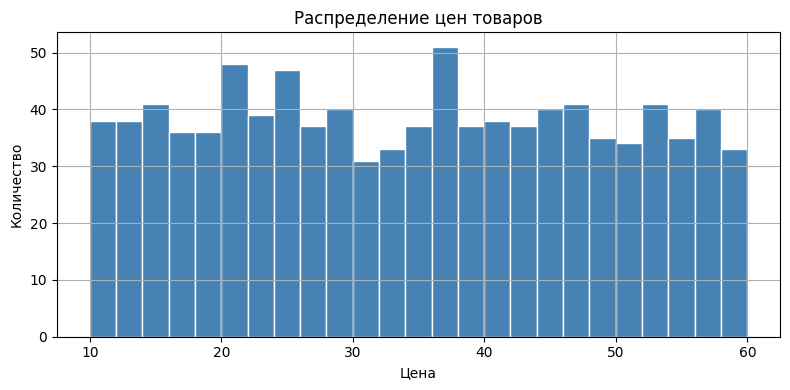

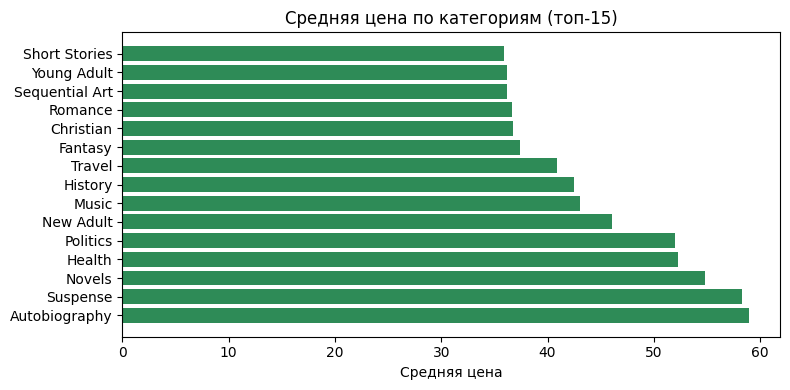

In [25]:
# График 1: распределение цен
plt.figure()
m["price"].dropna().hist(bins=25, color="steelblue", edgecolor="white")
plt.title("Распределение цен товаров")
plt.xlabel("Цена"); plt.ylabel("Количество")
plt.tight_layout(); plt.show()

# График 2: средняя цена по категориям
plt.figure()
vc = v1.dropna(subset=["category"]).sort_values("средняя_цена", ascending=False).head(15)
plt.barh(vc["category"], vc["средняя_цена"], color="seagreen")
plt.title("Средняя цена по категориям (топ-15)")
plt.xlabel("Средняя цена")
plt.tight_layout(); plt.show()


 Графики показывают распределение цен и средние цены по категориям.

In [26]:
print("Итоговая раскладка трёх слоёв:")
for p in sorted(ROOT.rglob("*")):
    if p.is_file() and p.suffix in (".jsonl", ".parquet", ".csv", ".db", ".sql"):
        print(f"  {p.relative_to(ROOT)} — {p.stat().st_size / 1024:.1f} КБ")
conn.close()


Итоговая раскладка трёх слоёв:
  clean\bench_fmt.csv — 6249.2 КБ
  clean\bench_fmt.jsonl — 11551.5 КБ
  clean\bench_fmt.parquet — 122.0 КБ
  clean\dataset.parquet — 48.3 КБ
  clean\format_benchmark.csv — 0.3 КБ
  clean\rejects.jsonl — 0.9 КБ
  db\schema.sql — 2.0 КБ
  db\schema_pg.sql — 1.1 КБ
  db\warehouse.db — 772.0 КБ
  mart\snapshots\dt=2026-10-17\447e261f696d41e1b68e938f75d670c7-0.parquet — 24.4 КБ
  mart\snapshots\dt=2026-10-19\447e261f696d41e1b68e938f75d670c7-0.parquet — 51.1 КБ
  mart\views\categories_agg.parquet — 5.7 КБ
  mart\views\price_bands.parquet — 4.7 КБ
  mart\views\top_by_rating.parquet — 5.1 КБ
  nocode\nocode_result.csv — 0.1 КБ
  raw\api_comments.jsonl — 247.7 КБ
  raw\scrapy_books.jsonl — 277.4 КБ


Показаны файлы, созданные в ходе работы.